In [82]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
import warnings
import joblib
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import random



In [2]:
df = pd.read_csv('../others/household_power_consumption.txt',sep = ';',
                parse_dates={'dt':['Date','Time']},
                infer_datetime_format=True,
                low_memory=False, na_values=['nan','?'],
                index_col='dt')

C:\Users\stros\AppData\Local\Temp\ipykernel_22044\2276934123.py:1: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  df = pd.read_csv('../others/household_power_consumption.txt',sep = ';',
C:\Users\stros\AppData\Local\Temp\ipykernel_22044\2276934123.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv('../others/household_power_consumption.txt',sep = ';',
C:\Users\stros\AppData\Local\Temp\ipykernel_22044\2276934123.py:1: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df = pd.read_csv('../others/household_power_consump

In [3]:
import pandas as pd

# 1) Keep only the 'Global_active_power' column
df = df[['Global_active_power']].copy()

# 2) Ensure index is datetime
df.index = pd.to_datetime(df.index)

# 3) Count NaNs before filling
n_nans_before = df['Global_active_power'].isna().sum()

# 4) Fill NaNs using mean of previous and next non-NaN values
s = df['Global_active_power']
prev = s.ffill()
nxt  = s.bfill()
mask = s.isna()
s.loc[mask] = (prev[mask] + nxt[mask]) / 2
df['Global_active_power'] = s

# 5) Count NaNs after filling
n_nans_after = df['Global_active_power'].isna().sum()

# 6) Print the stats
print(f"NaNs before filling: {n_nans_before}")
print(f"NaNs after filling:  {n_nans_after}")


NaNs before filling: 25979
NaNs after filling:  0


In [4]:
print(len(df))
# 1) Ensure index is datetime (in case it's not already)
df.index = pd.to_datetime(df.index)

# 2) Resample to 15-minute averages
df_15min = df.resample('15T').mean()

print(df_15min.head())
print(len(df_15min))


2075259
                     Global_active_power
dt                                      
2006-12-16 17:15:00             4.587333
2006-12-16 17:30:00             4.140667
2006-12-16 17:45:00             4.159333
2006-12-16 18:00:00             4.121067
2006-12-16 18:15:00             3.768533
138352


C:\Users\stros\AppData\Local\Temp\ipykernel_22044\2107327529.py:6: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  df_15min = df.resample('15T').mean()


In [5]:
print(df_15min['Global_active_power'].min())

0.078


In [10]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ————————————————————————————————————————————————————————————————————————
# 1) Prepare your single series
# ————————————————————————————————————————————————————————————————————————
df = (
    df_15min
    .rename_axis('Time')
    .reset_index()
    .assign(Time=lambda d: pd.to_datetime(d['Time'], errors='coerce'))
    .sort_values('Time')
    .reset_index(drop=True)
)

# ————————————————————————————————————————————————————————————————————————
# 2) ACF & PACF on a random window (here x=1 → full series)
# ————————————————————————————————————————————————————————————————————————
N = len(df)
window_size = N  # full series
start = 0       # since window_size == N
window = df.iloc[start : start + window_size]
ts = window.set_index('Time')['Global_active_power']

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(ts, lags=50, ax=axes[0])
#axes[0].set_title(f"ACF (full series, {window_size} points)")
plot_pacf(ts, lags=50, ax=axes[1])
#axes[1].set_title(f"PACF (full series, {window_size} points)")
plt.tight_layout()
plt.savefig("acf_pacf_full_series.pdf")
plt.close()

# ————————————————————————————————————————————————————————————————————————
# 3) Seasonal decomposition + FFT + differencing (no aggregation)
# ————————————————————————————————————————————————————————————————————————
def analyze_and_plot(df, variable='Global_active_power',
                     differencing=False, file_prefix="series"):
    # Clean & optionally difference
    df = df.copy()
    df[variable] = df[variable].fillna(df[variable].mean())
    if differencing:
        df[variable] = df[variable].diff()
    df = df.dropna(subset=[variable])

    # Seasonal decomposition (assumes daily cycle = 24 pts of 1h? 
    # but since you’re 15 min freq, 24h = 24*4 = 96)
    period = 96  
    decomp = seasonal_decompose(df[variable], model='additive', period=period)
    fig, axes = plt.subplots(4, 1, figsize=(10, 8))
    decomp.observed .plot(ax=axes[0], title="Observed")
    decomp.trend    .plot(ax=axes[1], title="Trend")
    decomp.seasonal.plot(ax=axes[2], title="Seasonal")
    decomp.resid    .plot(ax=axes[3], title="Residual")
    plt.tight_layout()
    plt.savefig(f"{file_prefix}_decomposition.pdf")
    plt.close()

    # FFT
    dt = df['Time'].diff().dt.total_seconds().mean()
    fs = 1.0 / dt
    signal = df[variable].values
    n = len(signal)
    fft_res   = np.fft.fft(signal)
    fft_res   = fft_res / len(df_15min)
    freq      = np.fft.fftfreq(n, d=1/fs)
    fft_shift = np.fft.fftshift(fft_res)
    freq_shift= np.fft.fftshift(freq)

    # reference periods (in seconds)
    periods = {
        "6 h":  6*3600,
        "12 h":12*3600,
        "24 h":24*3600,
        "1 w": 7*24*3600
    }
    freqs = {lbl: 1.0/p for lbl,p in periods.items()}

    # your original line‐style mapping
    styles = {
        "6 h":   'dotted',
        "12 h":  'dashed',
        "24 h":  'solid',
        "1 w":   'dashdot'
    }

    # pick a 4-color palette (you can swap 'tab10' for any other)
    import matplotlib.cm as cm, matplotlib.colors as mcolors
    cmap = cm.get_cmap('Accent', len(styles))
    # map each label to a distinct color
    colors = {lbl: cmap(i) for i,lbl in enumerate(styles)}

    plt.figure(figsize=(10,6))
    plt.plot(freq_shift[n//2:], np.abs(fft_shift[n//2:]))
    plt.xscale('log')

    for lbl, f0 in freqs.items():
        plt.axvline(
            x=f0,
            linestyle=styles[lbl],
            color=colors[lbl],
            alpha=0.5,
            label=lbl
        )
    plt.xlabel("Frequency (Hz)")
    plt.ylim(top = 1, bottom = 0)
    plt.ylabel("Amplitude in kW")
    plt.legend()
    plt.grid(which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.savefig(f"{file_prefix}_fft.pdf")
    plt.close()

# run it on your df
analyze_and_plot(df, variable='Global_active_power',
                 differencing=False, file_prefix="global_active_power")

# ————————————————————————————————————————————————————————————————————————
# 4) Polynomial trend fit over full series
# ————————————————————————————————————————————————————————————————————————
df_fit = df.dropna(subset=['Global_active_power'])
x_vals = np.arange(len(df_fit))
y_vals = df_fit['Global_active_power'].values
coeffs = np.polyfit(x_vals, y_vals, 10)
trend  = np.poly1d(coeffs)(x_vals)

plt.figure(figsize=(12,6))
plt.plot(df_fit['Time'], y_vals,   label='Observed', alpha=0.6)
plt.plot(df_fit['Time'], trend,    label='10th‐degree fit', color='red')
plt.xlabel("Time")
plt.ylabel("Global_active_power")
plt.legend()
plt.tight_layout()
plt.savefig("polyfit_full_series.pdf")
plt.close()


C:\Users\stros\AppData\Local\Temp\ipykernel_22044\3214332731.py:94: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('Accent', len(styles))


                 Time  Global_active_power   Hour Month_Name        Date
0 2006-12-16 17:15:00             4.587333  17.25   December  2006-12-16
1 2006-12-16 17:30:00             4.140667  17.50   December  2006-12-16
2 2006-12-16 17:45:00             4.159333  17.75   December  2006-12-16
3 2006-12-16 18:00:00             4.121067  18.00   December  2006-12-16
4 2006-12-16 18:15:00             3.768533  18.25   December  2006-12-16


C:\Users\stros\AppData\Local\Temp\ipykernel_20712\3527718449.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap   = cm.get_cmap('coolwarm', len(seasonal_order))


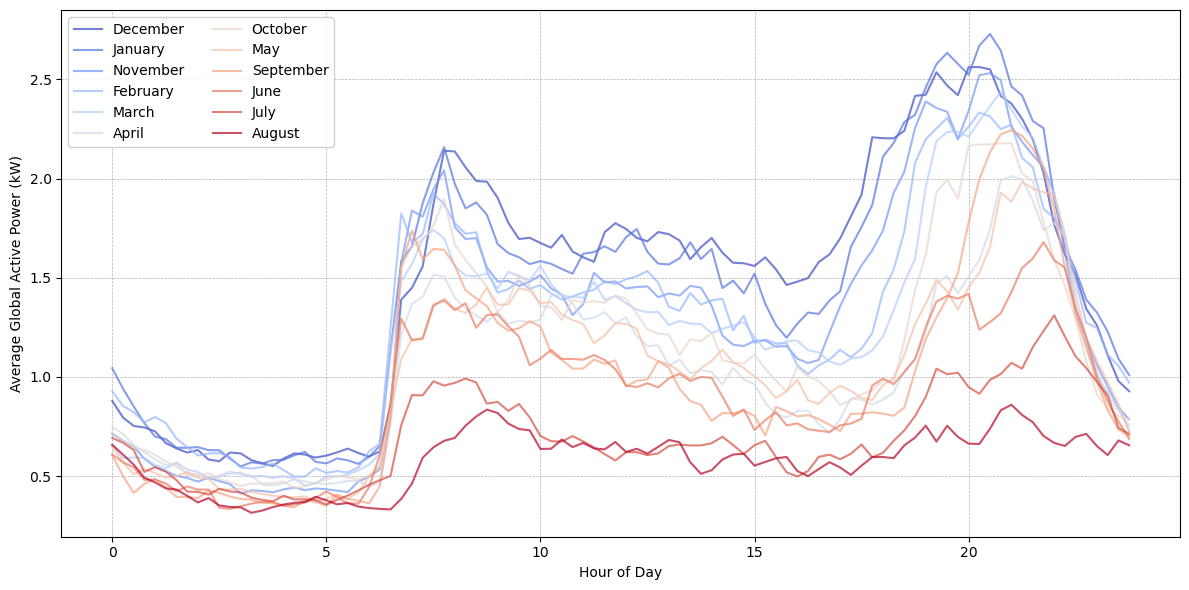

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm

# — assume df is your 15-min DataFrame with columns ["Time","Global_active_power"] —
df = df.dropna(subset=['Global_active_power']).copy()
df['Time'] = pd.to_datetime(df['Time'])
df['Hour']  = df['Time'].dt.hour + df['Time'].dt.minute/60.0
df['Month_Name'] = df['Time'].dt.month_name()
df['Date'] = df['Time'].dt.date
print(df.head())

# Define true seasonal order:
seasonal_order = [
    # Winter
    'December', 'January', 'November', 'February',
    # Spring
    'March', 'April', 'October', 'May',  'September',
    # Summer
    'June', 'July', 'August',
    # Autumn
   
]

# generate a blue-to-red colormap across the 12 months
cmap   = cm.get_cmap('coolwarm', len(seasonal_order))
colors = [cmap(i) for i in range(len(seasonal_order))]

plt.figure(figsize=(12, 6))

for idx, month in enumerate(seasonal_order):
    # subset the df to this month
    mdf = df[df['Month_Name'] == month]
    if mdf.empty:
        continue
    
    # compute the average daily profile for this month
    hourly = (mdf
              .groupby(['Date','Hour'])['Global_active_power']
              .mean()
              .reset_index()
              .groupby('Hour')['Global_active_power']
              .mean())
    
    plt.plot(hourly.index,
             hourly.values,
             label=month,
             color=colors[idx],
             alpha=0.7)

#plt.title("Average Daily Load Profile by Month (Seasonal Order)")
plt.xlabel("Hour of Day")
plt.ylabel("Average Global Active Power (kW)")
plt.grid(True, linestyle='--', linewidth=0.5)
plt.legend(loc='upper left', ncol=2, framealpha=0.9)
plt.tight_layout()
plt.savefig("seasonal_monthly_profiles.pdf")
plt.show()
df = df.drop(columns=['Month_Name'], axis=1)

Missing values (% of col):
Time                   0.0
Global_active_power    0.0
Hour                   0.0
Date                   0.0
dtype: float64
Columns: ['Time', 'Global_active_power', 'Hour', 'Date'] 

Applied Box–Cox on 'Global_active_power' with λ = -0.0690


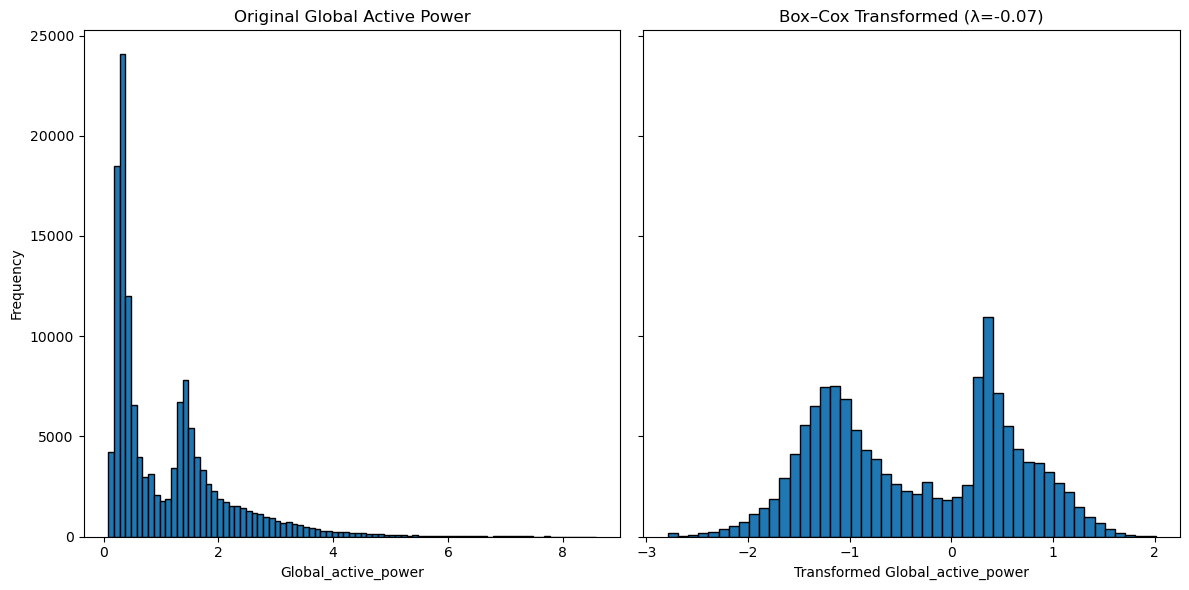

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox

def preprocess_df(df):
    """
    Preprocess a single DataFrame with only 'Time' & 'Global_active_power':
      - Report % missing
      - Parse & sort 'Time'
      - Create hour/minute/day/month features
    """
    df = df.copy()
    print("Missing values (% of col):")
    print((df.isnull().mean() * 100).round(2))
    print("Columns:", df.columns.tolist(), "\n")

    # 1) Parse Time
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    if df['Time'].isnull().any():
        print("⚠️  Some Time values became NaT!")
    df = df.dropna(subset=['Time'])

    # 2) Sort & reset
    df = df.sort_values('Time').reset_index(drop=True)

    # 3) Time-based features
    df['hour']   = df['Time'].dt.hour
    df['minute'] = df['Time'].dt.minute
    df['day']    = df['Time'].dt.day
    df['month']  = df['Time'].dt.month

    return df

def add_lag_features(df, column, lag_steps=None):
    """
    Add:
      - 1‐row lag of `column`
      - fixed‐frequency lags for each suffix→step_count in lag_steps
    """
    df = df.copy().set_index('Time').sort_index()

    # 1-row lag
    df[f'{column}_lag_1'] = df[column].shift(1)

    # time‐based lags, specified in numbers of 15-min periods
    if lag_steps is None:
        lag_steps = {
            '6H':   6 * 4,
            '12h': 12 * 4,
            '24h': 24 * 4,
            '168h':168 * 4
        }
    for suffix, periods in lag_steps.items():
        df[f'{column}_{suffix}'] = df[column].shift(periods)

    return df.reset_index()

def apply_boxcox(df, column, lmbda=None):
    """
    Apply a pure Box–Cox transform (no shift!) to `df[column]`.
    Returns (λ, new_df). Raises if any values ≤ 0.
    """
    arr = df[column].values
    if np.any(arr <= 0):
        raise ValueError(f"Column '{column}' must be > 0 for Box–Cox")

    if lmbda is None:
        transformed, lmbda_ = boxcox(arr)
    else:
        transformed = boxcox(arr, lmbda)
        lmbda_ = lmbda

    new_df = df.copy()
    new_df[column] = transformed
    print(f"Applied Box–Cox on '{column}' with λ = {lmbda_:.4f}")
    return lmbda_, new_df

# ─── Now: run everything on your single 15-min series ──────────────────────
# assume `df` is already loaded as your 15-min DataFrame

# 1) Preprocess
df_clean = preprocess_df(df)

# 2) Add lags
df_lagged = add_lag_features(
    df_clean,
    column='Global_active_power',
    lag_steps={
        '6H':   6 * 4,
        '12h': 12 * 4,
        '24h': 24 * 4,
        '168h':168 * 4
    }
)

# 3) Drop any NaNs introduced by lagging
lag_cols = [c for c in df_lagged.columns if c.startswith('Global_active_power')]
df_lagged = df_lagged.dropna(subset=lag_cols)

# 4) Plot before/after histograms
orig_vals = df_lagged['Global_active_power'].values.copy()

# Apply Box–Cox
lmbda, df_transformed = apply_boxcox(df_lagged, 'Global_active_power')
trans_vals = df_transformed['Global_active_power'].values

binwidth   = 0.1
bins_orig  = np.arange(orig_vals.min(),  orig_vals.max()  + binwidth, binwidth)
bins_trans = np.arange(trans_vals.min(), trans_vals.max() + binwidth, binwidth)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].hist(orig_vals,  bins=bins_orig,  edgecolor='black')
axes[0].set_title("Original Global Active Power")
axes[0].set_xlabel("Global_active_power")
axes[0].set_ylabel("Frequency")

axes[1].hist(trans_vals, bins=bins_trans, edgecolor='black')
axes[1].set_title(f"Box–Cox Transformed (λ={lmbda:.2f})")
axes[1].set_xlabel("Transformed Global_active_power")

plt.tight_layout()
plt.savefig('histograms_global_active_power.pdf')
plt.show()


In [ ]:
print(df_transformed['Global_active_power'].min())
import numpy as np

def create_supervised_data_and_split(df,
                                     static_features,
                                     lag_features,
                                     target_feature,
                                     train_size=96*30,
                                     tune_size=96*10):
    """
    Build X,y for one series so that:
      • static_features come from df.loc[i]
      • lag_features come from df.loc[i] (already pre-computed)
    Then split into train/tune/test by counts.

    Assumes df has NO NaNs in any of static_features + lag_features + [target_feature],
    and is already sorted by time.
    """
    # 1) Stack static + lag features into X, and target into y
    X_static = df[static_features].values        # shape (n, len(static_features))
    X_lags   = df[lag_features].values           # shape (n, len(lag_features))
    X_all    = np.hstack([X_static, X_lags])     # shape (n, total_features)
    y_all    = df[target_feature].values         # shape (n,)

    # 2) Split by counts
    end_train = train_size
    end_tune  = train_size + tune_size

    X_train, y_train = X_all[:end_train], y_all[:end_train]
    X_tune,  y_tune  = X_all[end_train:end_tune], y_all[end_train:end_tune]
    X_test,  y_test  = X_all[end_tune:],       y_all[end_tune:]

    return X_train, y_train, X_tune, y_tune, X_test, y_test

# ─── Example usage ─────────────────────────────────────────────────────────
# after preprocessing+lagging, df has columns:
#   ['Time', 'hour','minute','day','month',
#    'Global_active_power', 'Global_active_power_lag_1', 'Global_active_power_6H', ... ]

# 1) Drop NaNs (from initial lag creation) and reset index
df_transformed = df_transformed.dropna(
    subset=['hour','minute','day','month'] + 
           [c for c in df_transformed.columns if c.startswith('Global_active_power_')]
).reset_index(drop=True)

# 2) Define feature lists
static_feats = ['hour','minute','day','month']
lag_feats    = [c for c in df_transformed.columns 
                if c.startswith('Global_active_power_') 
                and c not in ['Global_active_power']]  # picks up '_lag_1', '_6H', etc.

# 3) Build & split
X_train, y_train, X_val, y_val, X_test, y_test = create_supervised_data_and_split(
    df=df_transformed,
    static_features=static_feats,
    lag_features=lag_feats,
    target_feature='Global_active_power',
    train_size=96*30,   # e.g. first 30 days
    tune_size=96*21     # next 10 days
)

# 4) Shapes
print("Train:", X_train.shape, y_train.shape)
print("Tune: ", X_val.shape,   y_val.shape)
print("Test: ", X_test.shape,  y_test.shape)

import joblib
train_ds = {
    'X_train': X_train,
    'y_train': y_train
}
tune_ds = {
    'X_tune': X_val,
    'y_tune': y_val
}
test_ds = {
    'X_test': X_test,
    'y_test': y_test
}

# Ensure the output directory exists
os.makedirs("processed_data", exist_ok=True)

# Write each to disk
joblib.dump(train_ds, "processed_data/training_dataset_series1.joblib")
joblib.dump(tune_ds,  "processed_data/tuning_dataset_series1.joblib")
joblib.dump(test_ds,  "processed_data/testing_dataset_series1.joblib")

print("Datasets saved to 'processed_data/'")

def inverse_boxcox_transform(y_trans, lmbda):
    """
    Invert the Box–Cox transform:
      If λ ≠ 0:  y = (y_trans*λ + 1) ** (1/λ)
      If λ = 0:  y = exp(y_trans)
    """
    y_trans = np.asarray(y_trans)
    if lmbda == 0:
        return np.exp(y_trans)
    return np.power(lmbda * y_trans + 1, 1.0 / lmbda)


In [157]:
# ─── preprocessing_and_split.py ─────────────────────────────────────────────
import os
import joblib
import numpy as np
import pandas as pd
from scipy.stats import boxcox

# ————————————————————————————————————————————————————————————————————————
# 1) Prepare your single series
# ————————————————————————————————————————————————————————————————————————
df_raw = (
    df_15min
    .rename_axis('Time')
    .reset_index()
    .assign(Time=lambda d: pd.to_datetime(d['Time'], errors='coerce'))
    .sort_values('Time')
    .reset_index(drop=True)
)

def preprocess_and_lag(df):
    # 1) parse & sort time + time‐features
    df = df.copy()
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')
    df = df.dropna(subset=['Time']).sort_values('Time').reset_index(drop=True)
    df['hour']   = df['Time'].dt.hour
    df['minute'] = df['Time'].dt.minute
    df['day']    = df['Time'].dt.day
    df['month']  = df['Time'].dt.month

    # 2) add lags (pure shifts on the ORIGINAL series)
    df = df.set_index('Time').sort_index()
    col = 'Global_active_power'
    for suffix, periods in {
        '6H':   6*4,   '12h': 12*4,
        '24h': 24*4,  '168h':168*4
    }.items():
        df[f'{col}_{suffix}'] = df[col].shift(periods)
    df = df.reset_index().dropna(subset=[col] + [c for c in df.columns if c.startswith(col+'_')])

    # 3) box‐cox transform (note swapped unpacking order)
    arr = df[col].values
    transformed, lmbda = boxcox(arr)
    df[col] = transformed
    print(f"Applied Box–Cox λ={lmbda:.4f}")

    return df, lmbda

# 4) now load & run
# assume `df_raw` is your 15-min DataFrame already read in
df_all, lmbda = preprocess_and_lag(df_raw)
print(df_all.columns)

# 5) split by time‐order into train / tune / test *DataFrames*
train_size = 96*30
tune_size  = 96*21
train_df = df_all.iloc[:train_size].reset_index(drop=True)
val_df   = df_all.iloc[train_size:train_size+tune_size].reset_index(drop=True)
test_df  = df_all.iloc[train_size+tune_size:].reset_index(drop=True)

static_feats = ['hour','minute','day','month']
lag_feats    = [c for c in df_all.columns 
                if c.startswith('Global_active_power_') and c!='Global_active_power' and  c!= 'Global_active_power_lag_1']

os.makedirs("processed_data", exist_ok=True)
joblib.dump({
    'train_df':      train_df,
    'val_df':        val_df,
    'test_df':       test_df,
    'static_feats':  static_feats,
    'lag_feats':     lag_feats,
    'boxcox_lambda': lmbda
}, "processed_data/series1_dfs.joblib")
print("Saved processed_data/series1_dfs.joblib")


Applied Box–Cox λ=-0.0690
Index(['Time', 'Global_active_power', 'hour', 'minute', 'day', 'month',
       'Global_active_power_6H', 'Global_active_power_12h',
       'Global_active_power_24h', 'Global_active_power_168h'],
      dtype='object')
Saved processed_data/series1_dfs.joblib


In [169]:
lag_feats

['Global_active_power_6H',
 'Global_active_power_12h',
 'Global_active_power_24h',
 'Global_active_power_168h']

In [160]:
import os
import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, ParameterGrid
from sklearn.metrics import mean_squared_error

# ─── 0) Load your processed DataFrames + feature lists ────────────────────
data = joblib.load("processed_data/series1_dfs.joblib")
print(data.keys())
train_df    = train_df
static_feats = data["static_feats"]

lag_feats    = data["lag_feats"]
# our target column after Box–Cox:
target_col   = "Global_active_power"

# build X_all, y_all in the same col‐order you used for training
X_all = train_df[static_feats + lag_feats].values
y_all = train_df[target_col].values

print(static_feats)
print(lag_feats)
print(X_all.shape, y_all.shape)

def forecast_batch_sequential(model, X_batch, static_feats, lag_feats, start_index):
    """
    Hardcoded sequential forecast with explicit lag updates:
    - Steps 0-23: Use true history for all lags.
    - Steps 24-47: Use preds 0-23 for 6H lags, true history for 12H/24H/168H.
    - Steps 48-95: Use preds 24-47 for 6H, preds 0-47 for 12H, true history for 24H/168H.
    - Steps 96+: Use preds for 24H lags as well.

    Args:
        model: Trained sklearn-like model.
        X_batch: Input array of shape (batch_size, n_features).
        static_feats: List of static feature names.
        lag_feats: List of lag feature names (e.g., ['Global_active_power_6H']).
        start_index: Absolute position of X_batch[0] in the full series.
    """
    import pandas as pd
    import numpy as np

    df = pd.DataFrame(X_batch, columns=static_feats + lag_feats).copy()
    B = len(df)
    preds = np.zeros(B, dtype=float)

    # Hardcoded lag steps (15-min intervals)
    LAG_STEPS = {
        "Global_active_power_6H": 24,      # 6 hours (24 steps)
        "Global_active_power_12h": 48,     # 12 hours (48 steps)
        "Global_active_power_24h": 96,     # 24 hours (96 steps)
        "Global_active_power_168h": 672    # 1 week (168 hours)
    }

    for i in range(B):
        # Current absolute position in the full series
        abs_i = start_index + i
        
        # Make prediction using current row
        xrow = df.iloc[i:i+1][static_feats + lag_feats].values
        yhat = model.predict(xrow)[0]
        preds[i] = yhat

        # 2. Update 6H lag (24 steps ahead) when we have 24 steps of history
        if abs_i >= 24 and i + 24 < B:
            df.at[i + 24, "Global_active_power_6H"] = yhat

        # 3. Update 12H lag (48 steps ahead) when we have 48 steps of history
        if abs_i >= 48 and i + 48 < B:
            df.at[i + 48, "Global_active_power_12h"] = yhat

        # 4. Update 24H lag (96 steps ahead) when we have 96 steps of history
        if abs_i >= 96 and i + 96 < B:
            df.at[i + 96, "Global_active_power_24h"] = yhat

        # Note: 168H lag is never updated in a 24h (96-step) forecast
        # (since 672 steps > 96)

    return preds


# ─── 2) set up CV + hyperparameter grid ──────────────────────────────────
batch_size = 96 * 10   # exactly the length of each validation fold
tscv = TimeSeriesSplit(n_splits=2, test_size=batch_size, gap=0)

param_grid = {
    'n_estimators':  [30, 50, 70],
    'max_depth':     [3, 5],
    'learning_rate': [0.05, 0.1]
}

best_score = np.inf
best_params = None

# ─── 3) manual grid-search using our sequential forecast ──────────────────
for params in ParameterGrid(param_grid):
    rmse_fold = []
    for train_idx, val_idx in tscv.split(X_all):
        X_tr, y_tr = X_all[train_idx], y_all[train_idx]
        X_val, y_val = X_all[val_idx], y_all[val_idx]

        m = GradientBoostingRegressor(**params, random_state=42)
        m.fit(X_tr, y_tr)

        # we know val_idx length == batch_size, so this is exactly one batch
        y_pred = forecast_batch_sequential(m, X_val, static_feats, lag_feats,  start_index=val_idx[0])
        rmse_fold.append(np.sqrt(mean_squared_error(y_val, y_pred)))

    cv_rmse = np.mean(rmse_fold)
    print(f"params={params} → CV-RMSE={cv_rmse:.4f}")
    if cv_rmse < best_score:
        best_score, best_params = cv_rmse, params

print(f"\n→ Best params: {best_params}, CV-RMSE={best_score:.4f}")

# ─── 4) Fit on all training data → save final model ───────────────────────
best_model = GradientBoostingRegressor(**best_params, random_state=42)
best_model.fit(X_all, y_all)

os.makedirs("saved_models", exist_ok=True)
joblib.dump(best_model, "saved_models/best_gbdt_model_1_month.joblib")
print("Saved sequentially-trained model to 'saved_models/best_gbdt_model_1_month.joblib'")


dict_keys(['train_df', 'val_df', 'test_df', 'static_feats', 'lag_feats', 'boxcox_lambda'])
['hour', 'minute', 'day', 'month']
['Global_active_power_6H', 'Global_active_power_12h', 'Global_active_power_24h', 'Global_active_power_168h']
(2880, 8) (2880,)
params={'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 30} → CV-RMSE=0.8745
params={'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50} → CV-RMSE=0.8950
params={'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 70} → CV-RMSE=0.8965
params={'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 30} → CV-RMSE=0.9711
params={'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 50} → CV-RMSE=0.9637
params={'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 70} → CV-RMSE=0.9484
params={'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 30} → CV-RMSE=0.9074
params={'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50} → CV-RMSE=0.8704
params={'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 70} → CV-RMSE=0

In [ ]:
joblib.dump(best_model,  "saved_models/best_gbdt_model_1_month.joblib")
joblib.dump(best_params_,   "saved_models/best_gbdt_params_1_month.joblib")

['saved_models/best_gbdt_params_1_month.joblib']

In [180]:
import os
import joblib
import numpy as np
from itertools import product
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
import plotly.graph_objects as go

from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.AccuracyUpdatedGBDT import AccuracyUpdatedGBDT

def expand(grid):
    """Yield all combinations of hyperparameters from `grid`."""
    for vals in product(*grid.values()):
        yield dict(zip(grid.keys(), vals))

# ─── 1) Load data, features, base model ───────────────────────────────────
import joblib

# 1) Load everything for series1 and inspect
data = joblib.load("processed_data/series1_dfs.joblib")
print("Available keys:", data.keys())

# 2) Extract your training DataFrame
#    (replace "train_df" below with the actual key if it's named differently)
tune_df = data["val_df"]

# 3) Feature lists
static_feats = data["static_feats"]
lag_feats    = data["lag_feats"]

# 4) Your target column (after inverse‐Box–Cox you’ll use this)
target_col = "Global_active_power"

# 5) Build your design matrix & target vector
X_all = train_df[static_feats + lag_feats].values
y_all = train_df[target_col].values

X_tune = tune_df[static_feats + lag_feats].values
y_tune = tune_df[target_col]
# 6) Quick sanity check
print("Static features:", static_feats)
print("Lag features   :", lag_feats)
print("X_all shape     :", X_tune.shape)
print("y_all shape     :", y_tune.shape)



base = joblib.load("saved_models/best_gbdt_model_1_month.joblib")

# ─── 2) Grids ───────────────────────────────────────────────────────────────
contrib_grid = {
    "m_threshold":          [0],
    "ratio_fixed_multiplier":[1, 1.25, 1.5],
    "alpha_multiplier":     [0.4, 0.7],
    "beta_multiplier":      [0.1, 0.3],
    "gamma_multiplier":     [0.1],
    "baseline":             [0]
}
ratio_grid = {
    "m_threshold":          [0],
    "ratio_fixed_multiplier":[1.2, 1.5, 1.8],
    "baseline":             [0]
}
accuracy_grid = {
    "sigmoid_k":      [1.6, 2.0, 2.4],
    "fixed_threshold":[0.6],
    "ratio_power":    [0.8],
    "w_scale":        [2]
}
static_grid = {
    "fixed_rebuild_count":[2, 5, 8],
    "m_threshold":        [50],
    "error_power":        [2]
}

# ─── 3) CV setup ───────────────────────────────────────────────────────────
batch_size      = 672
n_extra_batches = 3
n_batches       = X_tune.shape[0] // batch_size
tune_batches    = min(n_batches, n_extra_batches)
batch_ids       = np.arange(tune_batches)
tscv            = TimeSeriesSplit(n_splits=2, test_size=1, gap=0)

# ─── 4) Storage ────────────────────────────────────────────────────────────
methods = ["Index-Dynamic","Index-Static","Contrib","Ratio","Accuracy"]
cv_errors    = {m: np.inf for m in methods}
best_params  = {m: np.inf for m in methods}
tuned_models = {}

def forecast_batch_sequential(model, X_batch, static_feats, lag_feats, start_index):
    """
    Hardcoded sequential forecast with explicit lag updates:
    - Steps 0-23: Use true history for all lags.
    - Steps 24-47: Use preds 0-23 for 6H lags, true history for 12H/24H/168H.
    - Steps 48-95: Use preds 24-47 for 6H, preds 0-47 for 12H, true history for 24H/168H.
    - Steps 96+: Use preds for 24H lags as well.

    Args:
        model: Trained sklearn-like model.
        X_batch: Input array of shape (batch_size, n_features).
        static_feats: List of static feature names.
        lag_feats: List of lag feature names (e.g., ['Global_active_power_6H']).
        start_index: Absolute position of X_batch[0] in the full series.
    """
    import pandas as pd
    import numpy as np

    df = pd.DataFrame(X_batch, columns=static_feats + lag_feats).copy()
    B = len(df)
    preds = np.zeros(B, dtype=float)

    # Hardcoded lag steps (15-min intervals)
    LAG_STEPS = {
        "Global_active_power_6H": 24,       # 6 hours (24 steps)
        "Global_active_power_12h": 48,       # 12 hours (48 steps)
        "Global_active_power_24h": 96,       # 24 hours (96 steps)
        "Global_active_power_168h": 672      # 1 week (168 hours)
    }

    for i in range(B):
        # Make prediction using current row
        xrow = df.iloc[i:i+1][static_feats + lag_feats].values
        yhat = model.predict(xrow)[0]
        preds[i] = yhat


        # 2. Update 6H lag (24 steps ahead) starting at step 24
        if i >= 24 and i + 24 < B:
            df.at[i + 24, "Global_active_power_6H"] = yhat

        # 3. Update 12H lag (48 steps ahead) starting at step 48
        if i >= 48 and i + 48 < B:
            df.at[i + 48, "Global_active_power_12h"] = yhat

        # 4. Update 24H lag (96 steps ahead) starting at step 96
        if i >= 96 and i + 96 < B:
            df.at[i + 96, "Global_active_power_24h"] = yhat

        if i >= 672 and i + 672 < B:
            df.at[i + 672, "Global_active_power_168h"] = yhat

    return preds
# —— Index-Static —— #
for cfg in expand(static_grid):
    errs = []
    for train_idx, test_idx in tscv.split(batch_ids):
        m = ElasticGBDT(pretrained_model=base, y_train=y_train,
                        m_threshold=cfg["m_threshold"],
                        error_metric=root_mean_squared_error)
        m.dynamic_rebuild = False
        m.fixed_rebuild_count = cfg["fixed_rebuild_count"]
        for b in train_idx:
            s,e = b*batch_size,(b+1)*batch_size
            m.update_index_based(X_tune[s:e], y_tune[s:e])
            m.build_incremental_trees(
                X_tune[s:e], y_tune[s:e]-m.predict(X_tune[s:e]),
                number_of_incremental_trees=cfg["fixed_rebuild_count"]
            )
        b = test_idx[0]; s,e = b*batch_size,(b+1)*batch_size
        y_pred = forecast_batch_sequential(m, X_tune[s:e], static_feats, lag_feats, start_index=s)
        errs.append(root_mean_squared_error(y_tune[s:e], y_pred))
    mean_err = np.mean(errs)
    if mean_err < cv_errors["Index-Static"]:
        cv_errors["Index-Static"] = mean_err
        best_params["Index-Static"] = cfg
        tuned_models["Index-Static"] = m

# —— Contrib-Weighted —— #
for cfg in expand(contrib_grid):
    errs = []
    for train_idx, test_idx in tscv.split(batch_ids):
        m = ElasticGBDT(pretrained_model=base, y_train=y_train,
                        error_metric=root_mean_squared_error, **cfg)
        for b in train_idx:
            s,e = b*batch_size,(b+1)*batch_size
            m.update_contribution_weighted_ratio(X_tune[s:e], y_tune[s:e])
        b = test_idx[0]; s,e = b*batch_size,(b+1)*batch_size
        y_pred = forecast_batch_sequential(m, X_tune[s:e], static_feats, lag_feats, start_index=s)
        errs.append(root_mean_squared_error(y_tune[s:e], y_pred))
    mean_err = np.mean(errs)
    if mean_err < cv_errors["Contrib"]:
        cv_errors["Contrib"] = mean_err
        best_params["Contrib"] = cfg
        tuned_models["Contrib"] = m

# —— Ratio-Based —— #
for cfg in expand(ratio_grid):
    errs = []
    for train_idx, test_idx in tscv.split(batch_ids):
        m = ElasticGBDT(pretrained_model=base, y_train=y_train,
                        error_metric=root_mean_squared_error, **cfg)
        for b in train_idx:
            s,e = b*batch_size,(b+1)*batch_size
            m.update_ratio_based(X_tune[s:e], y_tune[s:e])
        b = test_idx[0]; s,e = b*batch_size,(b+1)*batch_size
        y_pred = forecast_batch_sequential(m, X_tune[s:e], static_feats, lag_feats, start_index=s)
        errs.append(root_mean_squared_error(y_tune[s:e], y_pred))
    mean_err = np.mean(errs)
    if mean_err < cv_errors["Ratio"]:
        cv_errors["Ratio"] = mean_err
        best_params["Ratio"] = cfg
        tuned_models["Ratio"] = m

# —— AccuracyUpdatedGBDT —— #
for cfg in expand(accuracy_grid):
    errs = []
    for train_idx, test_idx in tscv.split(batch_ids):
        m = AccuracyUpdatedGBDT(pretrained_model=base, y_train=y_train,
                                error_metric=mean_absolute_error, **cfg)
        m.weights = np.ones(len(m.trees))
        for b in train_idx:
            s,e = b*batch_size,(b+1)*batch_size
            m.update_weights_by_contribution_rel(X_tune[s:e], y_tune[s:e])
        b = test_idx[0]; s,e = b*batch_size,(b+1)*batch_size
        y_pred = forecast_batch_sequential(m, X_tune[s:e], static_feats, lag_feats, start_index=s)
        errs.append(root_mean_squared_error(y_tune[s:e], y_pred))
    mean_err = np.mean(errs)
    if mean_err < cv_errors["Accuracy"]:
        cv_errors["Accuracy"] = mean_err
        best_params["Accuracy"] = cfg
        tuned_models["Accuracy"] = m

# ─── 5) Save tuned models ──────────────────────────────────────────────────
os.makedirs("saved_models", exist_ok=True)
for name, model in tuned_models.items():
    fname = name.lower().replace('-', '_').replace(' ', '_')
    print(f"Saving {name} model to 'saved_models/{fname}_1.joblib'")
    joblib.dump(model, f"saved_models/{fname}_1.joblib")

# ─── 6) Report ─────────────────────────────────────────────────────────────
print("\nBest hyperparameters per model:")
for name in methods:
    print(f"{name:15s}: {best_params[name]}")

print("\nCV‐RMSE for each approach:")
for name in methods:
    print(f"{name:15s}: {cv_errors[name]:.4f}")


Available keys: dict_keys(['train_df', 'val_df', 'test_df', 'static_feats', 'lag_feats', 'boxcox_lambda'])
Static features: ['hour', 'minute', 'day', 'month']
Lag features   : ['Global_active_power_6H', 'Global_active_power_12h', 'Global_active_power_24h', 'Global_active_power_168h']
X_all shape     : (2016, 8)
y_all shape     : (2016,)
[Index-Based] 25 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 25 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 13 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 25 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 25 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 13 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 25 < 48 -> Full retraining.
Retraining triggered.
Retrained with 50 trees.
[Index-Based] 25 < 48 -> Full retraini

In [125]:
import copy
import joblib

plain      = joblib.load("saved_models/best_gbdt_model_1_month.joblib")
accuracy   = joblib.load("saved_models/accuracy_1.joblib")
index_dyn  = joblib.load("saved_models/index_dynamic_1.joblib")
index_stat = joblib.load("saved_models/index_static_1.joblib")
contrib    = joblib.load("saved_models/contrib_1.joblib")
ratio      = joblib.load("saved_models/ratio_1.joblib")
retrain    = copy.deepcopy(plain)

def get_tree_count(m):
    return len(getattr(m, "trees", getattr(m, "estimators_", [])))

print(index_dyn.get_tree_count())


AttributeError: 'ElasticGBDT' object has no attribute 'get_tree_count'

In [ ]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error
import joblib

param_grid = {
    'n_estimators': [20, 40],
    'max_depth':    [3, 4, 5, ],
    'learning_rate':[0.01, 0.1]
}

batch_size = 672
n_extra_batches = 3

final_plain_models = []
final_plain_params = []
joblib.load("processed_data/testing_dataset_series1.joblib")

for idx, data in enumerate(training_datasets, start=1):
    X_train, y_train = data['X_train'], data['y_train']
    X_test,  y_test  = testing_datasets[idx-1]['X_test'], testing_datasets[idx-1]['y_test']
    
    # how many full batches we actually have
    n_batches = X_test.shape[0] // batch_size
    extra_batches = min(n_extra_batches, n_batches)
    n_extra = extra_batches * batch_size

    # 1) carve off the first 23 batches from test
    X_extra, y_extra = X_test[:n_extra], y_test[:n_extra]

    # 2) form the expanded "training" set for tuning
    X_tune = np.vstack([X_train, X_extra])
    y_tune = np.concatenate([y_train, y_extra])

    print(f"\nSeries {idx}: tuning on {X_tune.shape[0]} samples "
          f"({len(X_train)} orig + {n_extra} extra)...")

    # 3) use TimeSeriesSplit with test_size = batch_size
    tscv = TimeSeriesSplit(n_splits=4, test_size=batch_size, gap=0)

    base = GradientBoostingRegressor(random_state=42)
    grid = GridSearchCV(
        estimator  = base,
        param_grid = param_grid,
        cv         = tscv,
        scoring    = 'neg_root_mean_squared_error',
        n_jobs     = 1,
        verbose    = 1
    )
    grid.fit(X_tune, y_tune)
    preds = grid.best_estimator_.predict(X_tune)
    # new: invert back to original scale
    preds = inverse_boxcox_transform(preds, lmbda)

    print(f" → Best params: {grid.best_params_}")
    print(f" → CV RMSE:    {-grid.best_score_:.4f}")

    final_plain_models.append(grid.best_estimator_)
    final_plain_params.append(grid.best_params_)

# save them for later
joblib.dump(final_plain_models, "final_plain_models.joblib")
joblib.dump(final_plain_params, "final_plain_params.joblib")
print(f"\nStored {len(final_plain_models)} final_plain_models.")



Series 1: tuning on 4032 samples (2016 orig + 2016 extra)...
Fitting 4 folds for each of 12 candidates, totalling 48 fits
 → Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 40}
 → CV RMSE:    0.5280

Stored 1 final_plain_models.


In [102]:
import sys, os

# 1) Add your project root (parent of `src/`) to sys.path

project_root = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2) Import your module object
from src.ensemble_methods import elasticGBDT
from src.ensemble_methods import AccuracyUpdatedGBDT 

# 3) Reload it when you’ve made changes
import importlib
importlib.reload(elasticGBDT)
importlib.reload(AccuracyUpdatedGBDT)

# 4) Now you can re-import classes from it if you like
from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.AccuracyUpdatedGBDT import AccuracyUpdatedGBDT

In [ ]:
import copy
import joblib
import time
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
from src.ensemble_methods.elasticGBDT import ElasticGBDT
from src.ensemble_methods.AccuracyUpdatedGBDT import AccuracyUpdatedGBDT

# ─── Helpers ───────────────────────────────────────────────────────────────
def get_tree_count(m):
    return len(getattr(m, "trees", getattr(m, "estimators_", [])))

def inverse_boxcox_transform(y, lmbda):
    y = np.asarray(y)
    if lmbda == 0:
        return np.exp(y)
    return (lmbda * y + 1) ** (1.0 / lmbda)

def plot_weight_evolution(wmat):
    """Plots accuracy‐model tree‐weights over batches via Plotly."""
    fig = go.Figure()
    n_batches, n_trees = wmat.shape
    for t in range(n_trees):
        fig.add_trace(go.Scatter(
            x=list(range(n_batches)),
            y=wmat[:, t],
            mode='lines',
            line=dict(width=1),
            showlegend=False
        ))
    fig.update_layout(
        title="AccuracyUpdatedGBDT: Tree‐Weight Evolution",
        xaxis_title="Batch Index",
        yaxis_title="Tree Weight"
    )
    fig.show()

def forecast_batch_sequential(model, X_batch, static_feats, lag_feats, start_index):
    """
    Hardcoded sequential forecast with explicit lag updates:
    - Steps 0-23: Use true history for all lags.
    - Steps 24-47: Use preds 0-23 for 6H lags, true history for 12H/24H/168H.
    - Steps 48-95: Use preds 24-47 for 6H, preds 0-47 for 12H, true history for 24H/168H.
    - Steps 96+: Use preds for 24H lags as well.

    Args:
        model: Trained sklearn-like model.
        X_batch: Input array of shape (batch_size, n_features).
        static_feats: List of static feature names.
        lag_feats: List of lag feature names (e.g., ['Global_active_power_6H']).
        start_index: Absolute position of X_batch[0] in the full series.
    """
    import pandas as pd
    import numpy as np

    df = pd.DataFrame(X_batch, columns=static_feats + lag_feats).copy()
    B = len(df)
    preds = np.zeros(B, dtype=float)

    # Hardcoded lag steps (15-min intervals)
    LAG_STEPS = {
        "Global_active_power_6H": 24,       # 6 hours (24 steps)
        "Global_active_power_12h": 48,       # 12 hours (48 steps)
        "Global_active_power_24h": 96,       # 24 hours (96 steps)
        "Global_active_power_168h": 672      # 1 week (168 hours)
    }

    for i in range(B):
        # Make prediction using current row
        xrow = df.iloc[i:i+1][static_feats + lag_feats].values
        yhat = model.predict(xrow)[0]
        preds[i] = yhat


        # 2. Update 6H lag (24 steps ahead) starting at step 24
        if i >= 24 and i + 24 < B:
            df.at[i + 24, "Global_active_power_6H"] = yhat

        # 3. Update 12H lag (48 steps ahead) starting at step 48
        if i >= 48 and i + 48 < B:
            df.at[i + 48, "Global_active_power_12h"] = yhat

        # 4. Update 24H lag (96 steps ahead) starting at step 96
        if i >= 96 and i + 96 < B:
            df.at[i + 96, "Global_active_power_24h"] = yhat

        # Note: 168H lag is never updated in a 24h (96-step) forecast
        # (since 672 steps > 96)

    return preds

# ─── Settings ─────────────────────────────────────────────────────────────
batch_size   = 96    # your batch size
drop_batches = 0     # how many batches at end to drop
lmbda        = -0.0690    # Box–Cox λ used in preprocessing


# ─── 1) Load models ───────────────────────────────────────────────────────
plain      = joblib.load("saved_models/best_gbdt_model_1_month.joblib")
accuracy   = joblib.load('saved_models/accuracy_1.joblib')
index_dyn  = ElasticGBDT(pretrained_model=copy.deepcopy(plain), y_train=y_train,
                        m_threshold=0, error_metric=mean_squared_error)
index_stat = joblib.load("saved_models/index_static_1.joblib")
contrib    = joblib.load('saved_models/contrib_1.joblib')
ratio      = joblib.load("saved_models/ratio_1.joblib")
retrain    = copy.deepcopy(plain)

models = {
    "Plain":      plain,
    "Accuracy":   accuracy,
    "Index-Dyn":  index_dyn,
    "Index-Stat": index_stat,
    "Contrib":    contrib,
    "Ratio":      ratio,
    "Retrain":    retrain,
}


# 1) Load everything for series1 and inspect
data = joblib.load("processed_data/series1_dfs.joblib")
print("Available keys:", data.keys())

# 2) Extract your training DataFrame
#    (replace "train_df" below with the actual key if it's named differently)
test_df = data["test_df"]

# 3) Feature lists
static_feats = data["static_feats"]
lag_feats    = data["lag_feats"]

# 4) Your target column (after inverse‐Box–Cox you’ll use this)
target_col = "Global_active_power"

# 5) Build your design matrix & target vector
X_test = test_df[static_feats + lag_feats].values
y_test = test_df[target_col].values

# 6) Quick sanity check
print("Static features:", static_feats)
print("Lag features   :", lag_feats)
print("X_all shape     :", X_test.shape)
print("y_all shape     :", y_test.shape)



base = joblib.load("saved_models/best_gbdt_model_1_month.joblib")

n_batches = X_test.shape[0] // batch_size
batches   = range(n_batches - drop_batches)

# ─── 3) Prepare storage ───────────────────────────────────────────────────
results     = {name: {"time": [], "mae": [], "mse": [], "rmse": [], "mape": []}
               for name in models}
series_true = {name: [] for name in models}
series_pred = {name: [] for name in models}

series_err  = {name: [] for name in models}
series_mse  = {name: [] for name in models}
series_rmse = {name: [] for name in models}
series_mape = {name: [] for name in models}

series_wts   = []
series_trees = {name: [] for name in models}

# ─── 4) Run each model over all batches ───────────────────────────────────
for name, m_orig in models.items():
    print(f"\n=== {name} ===")
    m = copy.deepcopy(m_orig)

    # init Accuracy weights
    if name == "Accuracy":
        m.weights = np.ones(get_tree_count(m))
        orig_trees = get_tree_count(m)

    for b in batches:
        Xb = X_test[b*batch_size:(b+1)*batch_size]
        yb = y_test[b*batch_size:(b+1)*batch_size]

        # 1) walk‐forward prediction on Box–Cox scale
        t0            = time.perf_counter()
        y_pred_trans  = forecast_batch_sequential(m, Xb, static_feats, lag_feats, start_index=b*batch_size)
        dt            = time.perf_counter() - t0

        # 2) invert Box–Cox and store
        preds         = inverse_boxcox_transform(y_pred_trans, lmbda)
        yb_inv        = inverse_boxcox_transform(yb,          lmbda)
        series_true[name].append(yb_inv)
        series_pred[name].append(preds)

        # 3) compute errors
        mae  = mean_absolute_error(yb_inv, preds)
        mse  = mean_squared_error(yb_inv, preds)
        rmse = np.sqrt(mse)
        mape = mean_absolute_percentage_error(yb_inv, preds)

        results[name]["time"].append(dt)
        results[name]["mae"].append(mae)
        results[name]["mse"].append(mse)
        results[name]["rmse"].append(rmse)
        results[name]["mape"].append(mape)

        series_err[name].append(mae)
        series_mse[name].append(mse)
        series_rmse[name].append(rmse)
        series_mape[name].append(mape)

        # 4) record Accuracy weights & prune/build
        if name == "Accuracy":
            removed = m.update_weights_by_contribution_rel(Xb, yb)
            cur     = len(m.weights)
            padded  = np.pad(m.weights, (0, orig_trees-cur),
                             mode='constant', constant_values=np.nan)
            pruned  = orig_trees - get_tree_count(m)
            if pruned > 0:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), pruned)
            series_wts.append(padded)

        # 5) update / prune / rebuild for other models
        if name == "Retrain":
            m.fit(Xb, yb)
        elif name == "Index-Dyn":
            bef = get_tree_count(m)
            m, _ = m.update_index_based(Xb, yb)
            pr = bef - get_tree_count(m)
            if pr > 0:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), pr)
        elif name == "Index-Stat":
            bef = get_tree_count(m)
            m, pr = m.update_index_based(Xb, yb)
            cnt = m.number_of_incremental_trees
            m.build_incremental_trees(Xb, yb - m.predict(Xb), cnt)
            series_trees[name].append(get_tree_count(m))
        elif name == "Contrib":
            bef = get_tree_count(m)
            m.update_contribution_weighted_ratio(Xb, yb)
            pr = bef - get_tree_count(m)
            if pr > 0:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), pr)
        elif name == "Ratio":
            bef = get_tree_count(m)
            m.update_ratio_based(Xb, yb)
            pr = bef - get_tree_count(m)
            if pr > 0:
                m.build_incremental_trees(Xb, yb - m.predict(Xb), pr)

    # report average
    r = results[name]
    print(f"Avg time={np.mean(r['time']):.4f}s, MAE={np.mean(r['mae']):.4f}, RMSE={np.mean(r['rmse']):.4f}")
    if name == "Accuracy":
        plot_weight_evolution(np.vstack(series_wts))

# ─── 5) Plotly: True vs Predicted over full test ──────────────────────────
for name in models:
    y_true_all = np.concatenate(series_true[name])
    y_pred_all = np.concatenate(series_pred[name])
    x_axis     = np.arange(len(y_true_all))

    fig = go.Figure([
        go.Scatter(x=x_axis, y=y_true_all,
                   mode='lines', name='True',    line=dict(width=1)),
        go.Scatter(x=x_axis, y=y_pred_all,
                   mode='lines', name='Predicted', line=dict(width=1))
    ])
    fig.update_layout(
        title=f"{name} — True vs Predicted (full test)",
        xaxis_title="Sample Index",
        yaxis_title="Global_active_power",
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01)
    )
    fig.show()


Available keys: dict_keys(['train_df', 'val_df', 'test_df', 'static_feats', 'lag_feats', 'boxcox_lambda'])


Static features: ['hour', 'minute', 'day', 'month']
Lag features   : ['Global_active_power_6H', 'Global_active_power_12h', 'Global_active_power_24h', 'Global_active_power_168h']
X_all shape     : (132784, 8)
y_all shape     : (132784,)

=== Plain ===
Avg time=0.0427s, MAE=0.6951, RMSE=0.8901

=== Accuracy ===
Avg time=0.3316s, MAE=0.6940, RMSE=0.8894



=== Index-Dyn ===
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 1 trees. Now 49 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 31 trees. Now 19 remain.
[Index-Based] Pruned 40 trees. Now 10 remain.
[Index-Based] Pruned 40 trees. Now 10 remain.
[Index-Based] Pruned 48 trees. Now 2 remain.
[Index-Based] Pruned 48 trees. Now 2 remain.
[Index-Based] Pruned 48 trees. Now 2 remain.
[Index-Based] Pruned 48 trees. Now 2 remain.
[Index-Based] Pruned 49 trees. Now 1 remain.
[Index-Based] Pruned 2 trees. Now 48 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 0 trees. Now 50 remain.
[Index-Based] Pruned 49 trees. Now 1 remain.
[Index-Based] Pruned 33 trees. No

Available keys: dict_keys(['train_df', 'val_df', 'test_df', 'static_feats', 'lag_feats', 'boxcox_lambda'])
Static features: ['hour', 'minute', 'day', 'month']
Lag features   : ['Global_active_power_6H', 'Global_active_power_12h', 'Global_active_power_24h', 'Global_active_power_168h']
X_all shape     : (132784, 8)
y_all shape     : (132784,)

=== Plain ===
Avg time=0.0427s, MAE=0.6951, RMSE=0.8901

=== Accuracy ===
Avg time=0.3316s, MAE=0.6940, RMSE=0.8894

In [136]:
# ── Persist everything from this run ──────────────────────────────────────────────
import joblib, time, os, numpy as np

# ---------- 1) Gather artefacts ---------------------------------------------------
run_artifacts = {
    # ─ settings you may want to reproduce the run
    "run_params": {
        "batch_size":   batch_size,
        "drop_batches": drop_batches,
        "lmbda":        lmbda,
        "n_batches":    n_batches,
    },

    # ─ data & metrics you accumulated
    "results":      results,
    "series_true":  series_true,
    "series_pred":  series_pred,
    "series_err":   series_err,
    "series_mse":   series_mse,
    "series_rmse":  series_rmse,
    "series_mape":  series_mape,

    # ─ diagnostic extras (may be empty)
    "series_wts":   np.vstack(series_wts) if len(series_wts) else None,
    "series_trees": series_trees,

    # ─ the (possibly mutated) models after the walk-forward loop
    "models":       models,
}

# ---------- 2) Choose a timestamped filename -------------------------------------
ts   = time.strftime("%Y%m%d_%H%M%S")           # e.g. 20250515_104512
fname = f"run_cache/series1_run_{ts}.joblib"    # adjust folder to taste
os.makedirs(os.path.dirname(fname), exist_ok=True)

# ---------- 3) Dump everything (compressed) --------------------------------------
joblib.dump(run_artifacts, fname, compress=3)
print(f"✅  Saved current run to: {fname}")


✅  Saved current run to: run_cache/series1_run_20250515_111504.joblib


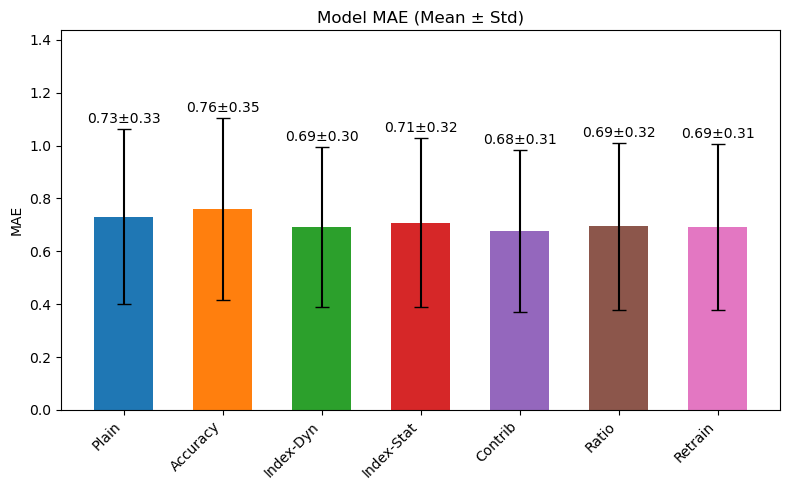

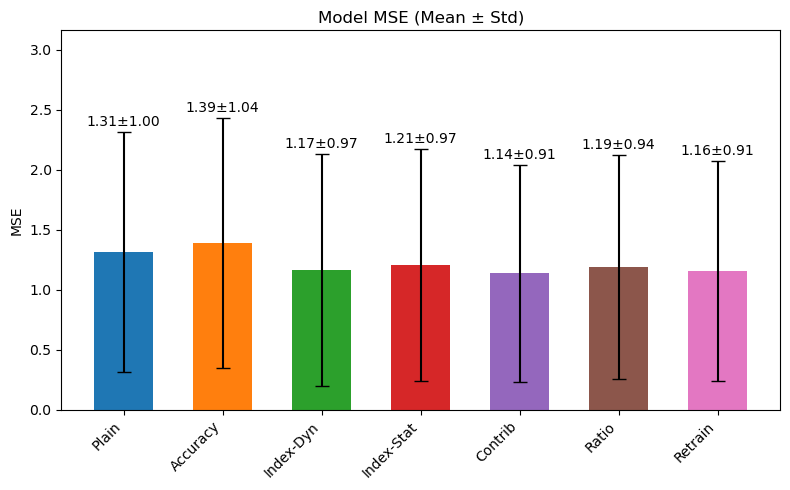

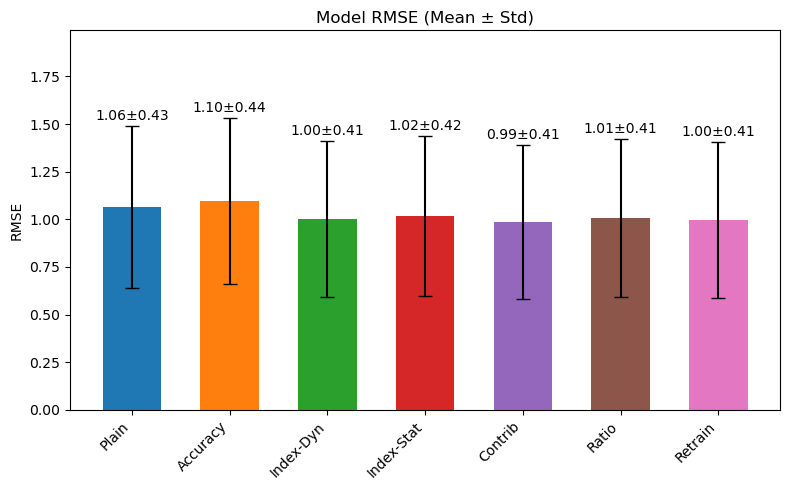

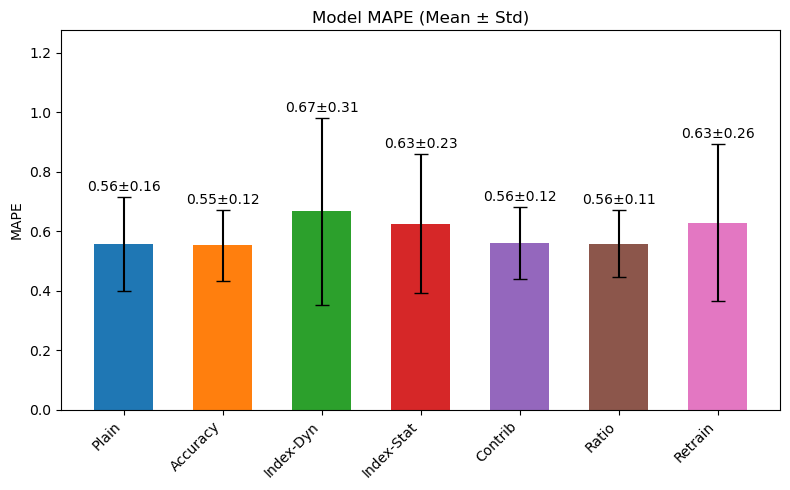

In [135]:
import numpy as np
import matplotlib.pyplot as plt

# --- models list and metric_series assumed defined as before ---
ms = list(models.keys())

metric_series = {
    'MAE':  series_err,
    'MSE':  series_mse,
    'RMSE': series_rmse,
    'MAPE': series_mape
}

# Precompute means and stds for each metric & model
means = {}
stds  = {}
for metric, data in metric_series.items():
    arr = np.array([data[name] for name in ms])      # shape (n_models, n_batches)
    means[metric] = arr.mean(axis=1)
    stds[metric]  = arr.std(axis=1)

# Plot setup
x = np.arange(len(ms))
width = 0.6

# Standard “tab:” colours
std_colors = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red',
    'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray',
    'tab:olive', 'tab:cyan'
]
colors = std_colors[:len(ms)]

# Loop over metrics and make one plot each
for metric in metric_series:
    fig, ax = plt.subplots(figsize=(8,5))
    bar = ax.bar(
        x,
        means[metric],
        width=width,
        yerr=stds[metric],
        capsize=5,
        color=colors
    )

    # Annotate each bar above the error bar with “mean±std”
    for idx, (m, s) in enumerate(zip(means[metric], stds[metric])):
        y_top = m + s
        ax.text(
            x[idx],
            y_top + 0.01 * max(means[metric] + stds[metric]),
            f'{m:.2f}±{s:.2f}',
            ha='center', va='bottom'
        )

    ax.set_xticks(x)
    ax.set_xticklabels(ms, rotation=45, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'Model {metric} (Mean ± Std)')
    ax.set_ylim(0, max(means[metric] + stds[metric]) * 1.3)

    plt.tight_layout()
    fig.savefig(f'{metric.lower()}_6_weeks_training_plot.pdf')

plt.show()


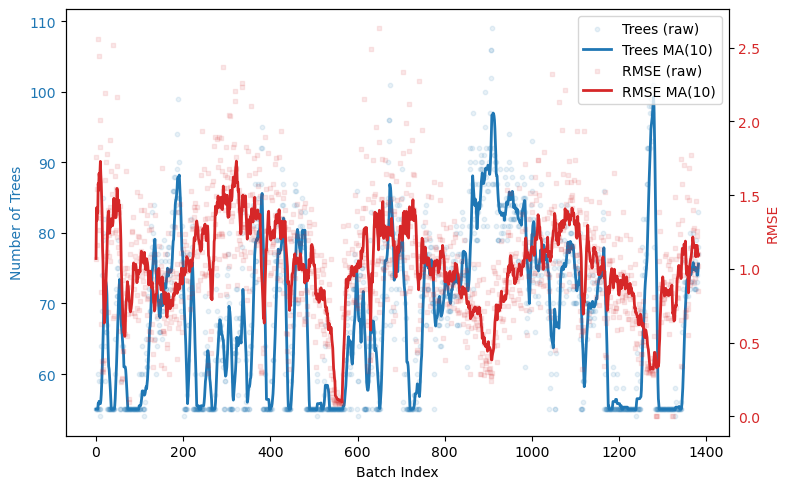

In [99]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

#  Plot Index-Stat: number of trees vs. RMSE over batches
trees  = series_trees['Index-Stat']   # list of tree counts per batch
rmse   = series_rmse['Index-Stat']    # list of RMSE per batch
b_idx  = np.arange(len(trees))

# compute 20‐batch moving averages
ma_window = 10
trees_ma = pd.Series(trees).rolling(ma_window, min_periods=1).mean().values
rmse_ma  = pd.Series(rmse).rolling(ma_window, min_periods=1).mean().values

fig, ax1 = plt.subplots(figsize=(8,5))

# Plot raw tree‐count points (very small & transparent)
color_t = 'tab:blue'
ax1.scatter(b_idx, trees,
            color=color_t,
            alpha=0.1,
            s=10,
            label='Trees (raw)')

# Plot trees moving average (solid line)
ax1.plot(b_idx, trees_ma,
         color=color_t,
         linewidth=2,
         linestyle='-',
         label=f'Trees MA({ma_window})')

ax1.set_xlabel('Batch Index')
ax1.set_ylabel('Number of Trees', color=color_t)
ax1.tick_params(axis='y', labelcolor=color_t)

# Twin axis for RMSE
ax2 = ax1.twinx()
color_r = 'tab:red'

# raw rmse points
ax2.scatter(b_idx, rmse,
            color=color_r,
            alpha=0.1,
            s=10,
            marker='s',
            label='RMSE (raw)')

# rmse moving average (solid line)
ax2.plot(b_idx, rmse_ma,
         color=color_r,
         linewidth=2,
         linestyle='-',
         label=f'RMSE MA({ma_window})')

ax2.set_ylabel('RMSE', color=color_r)
ax2.tick_params(axis='y', labelcolor=color_r)

# Legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

# Title and layout
fig.tight_layout()
plt.savefig('index_stat_trees_rmse_moving_average_6_weeks.pdf')
plt.show()


In [ ]:
import numpy as np
import pandas as pd

# ─── Assume you have these dicts already populated ─────────────────────────
# results: dict of model_name → dict with keys "time","mae","mse","rmse","mape",
#          each a list of per‐batch values
models = list(results.keys())

# ─── 1) Compute per‐model means ────────────────────────────────────────────
data = []
for name in models:
    r = results[name]
    data.append({
        "Model":     name,
        "AvgTime(s)": np.mean(r["time"]),
        "MAE":       np.mean(r["mae"]),
        "MSE":       np.mean(r["mse"]),
        "RMSE":      np.mean(r["rmse"]),
        "MAPE":      np.mean(r["mape"]),
    })
df = pd.DataFrame(data).set_index("Model")

# ─── 2) Find the best (min) value in each column ──────────────────────────
best = df.min()

# ─── 3) Define a formatter that bolds the best entry ──────────────────────
def bold_best(val, column):
    fmt = f"{val:.4f}"
    if np.isclose(val, best[column]):
        return r"\textbf{" + fmt + "}"
    return fmt

# ─── 4) Build a cell‐wise formatters dict ─────────────────────────────────
formatters = {
    col: (lambda v, c=col: bold_best(v, c))
    for col in df.columns
}

# ─── 5) Emit LaTeX ────────────────────────────────────────────────────────
latex = df.to_latex(
    column_format="l" + "r"*len(df.columns),
    float_format="%.4f",
    formatters=formatters,
    escape=False,                  # so that \textbf{…} survives
    caption="Six Weeks of Training",
    label="tab:results",
    position="!htb"
)

print(latex)


\begin{table}[!htb]
\caption{Six Weeks of Training}
\label{tab:results}
\begin{tabular}{lrrrrr}
\toprule
 & AvgTime(s) & MAE & MSE & RMSE & MAPE \\
Model &  &  &  &  &  \\
\midrule
Plain & \textbf{0.0002} & 0.1112 & 0.0468 & 0.1920 & 0.1859 \\
Accuracy & 0.0032 & \textbf{0.0952} & \textbf{0.0296} & \textbf{0.1543} & \textbf{0.1624} \\
Index-Dyn & 0.0032 & 0.3320 & 0.3444 & 0.5249 & 0.3829 \\
Index-Stat & 0.0087 & 0.3533 & 0.3535 & 0.5436 & 0.4256 \\
Contrib & 0.0041 & 0.2205 & 0.1531 & 0.3564 & 0.2492 \\
Ratio & 0.0040 & 0.2406 & 0.1805 & 0.3851 & 0.2698 \\
Retrain & 0.0003 & 0.3446 & 0.3580 & 0.5420 & 0.4029 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ─── Prepare output folder ─── #
out_dir = "pdf_plots_matplotlib"
os.makedirs(out_dir, exist_ok=True)

# ─── Loop over each model and save a PDF ─── #
for name in model_groups:
    # flatten all batches into one long vector
    y_true = np.concatenate(series_true[name])
    y_pred = np.concatenate(series_pred[name])
    x_axis = np.arange(len(y_true))

    # create the figure
    plt.figure(figsize=(10, 6))
    plt.plot(x_axis, y_true, label="True", linewidth=1)
    plt.plot(x_axis, y_pred, label="Predicted", linewidth=1)
    plt.title(f"{name}: True vs. Predicted Over All Batches")
    plt.xlabel("Sample Index (concatenated batches)")
    plt.ylabel("Value")
    plt.legend(loc="upper left")
    plt.tight_layout()

    # save as PDF
    out_path = os.path.join(out_dir, f"{name}_true_vs_pred.pdf")
    plt.savefig(out_path, format="pdf")
    plt.close()

    print(f"Saved: {out_path}")


Saved: pdf_plots_matplotlib\Plain_true_vs_pred.pdf
Saved: pdf_plots_matplotlib\Accuracy_true_vs_pred.pdf


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ─── Prepare output folder ─── #
out_dir = "pdf_plots_matplotlib"
os.makedirs(out_dir, exist_ok=True)

# ─── Loop over each model and save a PDF ─── #
for name in model_groups:
    # flatten all batches into one long vector
    y_true = np.concatenate(series_true[name])
    y_pred = np.concatenate(series_pred[name])
    x_axis = np.arange(len(y_true))

    # create the figure
    plt.figure(figsize=(10, 6))
    plt.plot(x_axis, y_true, label="True", linewidth=1)
    plt.plot(x_axis, y_pred, label="Predicted", linewidth=1)
    plt.title(f"{name}: True vs. Predicted Over All Batches")
    plt.xlabel("Sample Index (concatenated batches)")
    plt.ylabel("Value")
    plt.legend(loc="upper left")
    plt.tight_layout()

    # save as PDF
    out_path = os.path.join(out_dir, f"{name}_true_vs_pred.pdf")
    plt.savefig(out_path, format="pdf")
    plt.close()

    print(f"Saved: {out_path}")


Saved: pdf_plots_matplotlib\Plain_true_vs_pred.pdf
Saved: pdf_plots_matplotlib\Accuracy_true_vs_pred.pdf


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

# 1) Compute global y-axis bounds across all models
all_rmse = np.hstack([series_rmse[name] for name in model_groups])
y_min, y_max = all_rmse.min(), all_rmse.max()

# 2) Generate one PDF per model with an overfitted polynomial line
for name in model_groups:
    x = np.arange(len(series_rmse[name]))
    y = np.array(series_rmse[name])
    
    # Fit a high-degree polynomial (degree = len(x)-1) for 'overfitting'
    degree = len(x) - 1
    # Optional: cap degree to avoid numerical issues
    max_degree = 10
    if degree > max_degree:
        degree = max_degree
    
    coeffs = np.polyfit(x, y, degree)
    poly   = np.poly1d(coeffs)
    y_fit  = poly(x)

    # Create figure
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(x, y, color='blue', label='RMSE data points')
    ax.plot(x, y_fit, color='red', linestyle='-', linewidth=2, label=f'Degree-{degree} fit')
    ax.set_title(f"Series #{idx+1} – {name}: RMSE per Batch")
    ax.set_xlabel("Batch Index")
    ax.set_ylabel("RMSE")
    ax.set_ylim(y_min, y_max)
    ax.legend()
    plt.tight_layout()

    # Save to its own PDF
    output_pdf = f"rmse_series_{idx+1}_{name}.pdf"
    with PdfPages(output_pdf) as pdf:
        pdf.savefig(fig)
    plt.close(fig)

    print(f"Saved overfitted RMSE plot for {name} to {output_pdf}")


Saved overfitted RMSE plot for Plain to rmse_series_1_Plain.pdf
Saved overfitted RMSE plot for Accuracy to rmse_series_1_Accuracy.pdf


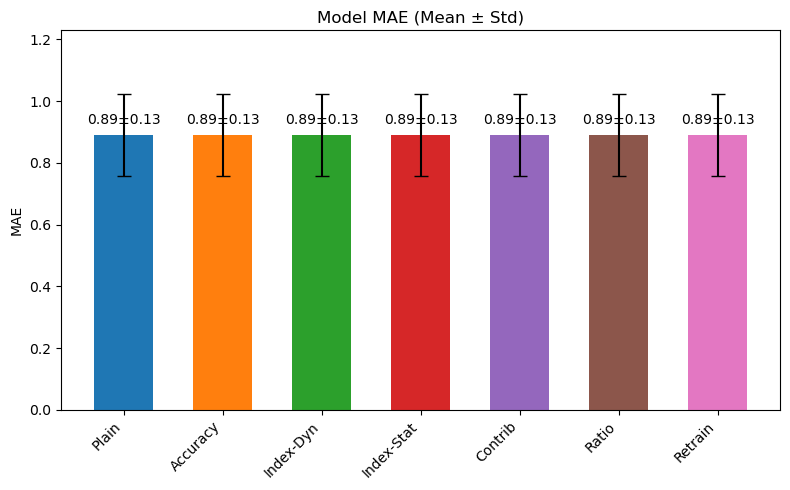

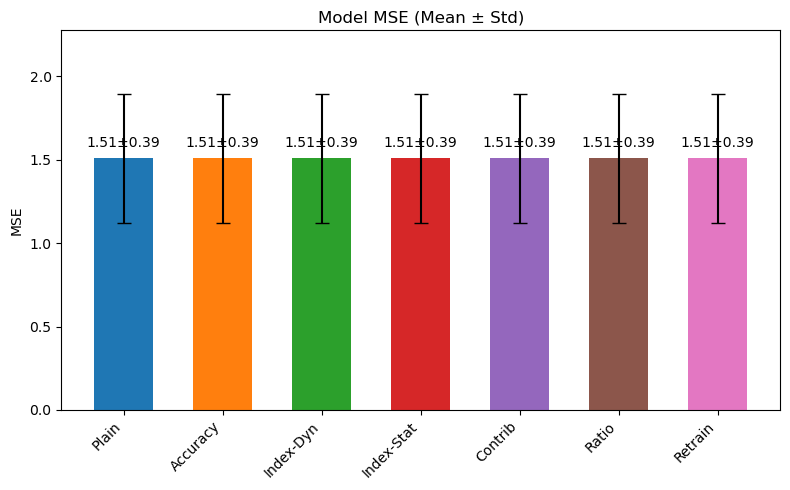

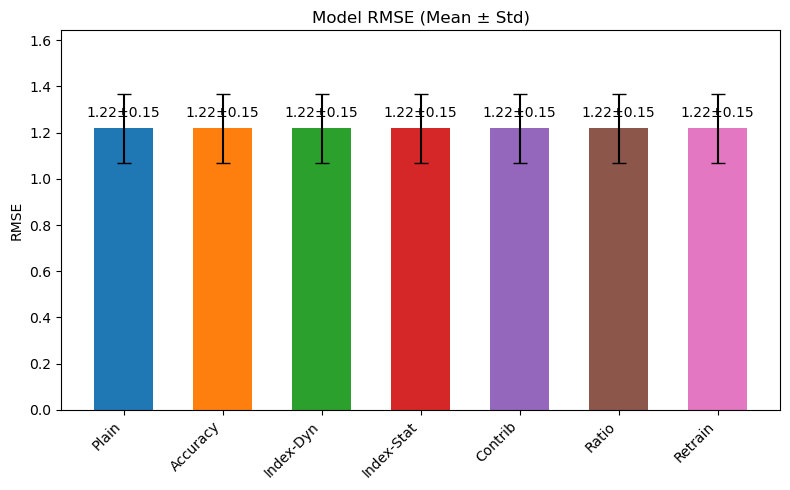

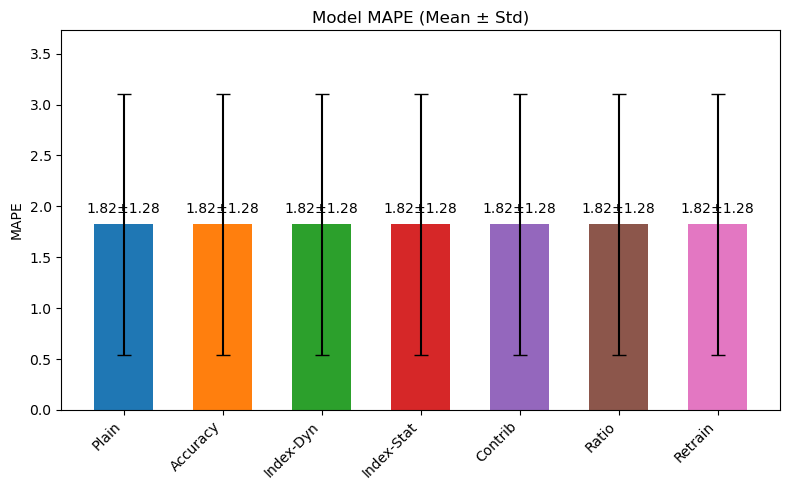

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Assume these dicts are already populated in your evaluation script: ---
# model_groups: dict of model_name -> list_of_models
# series_err:   dict of model_name -> list of MAE per batch
# series_mse:   dict of model_name -> list of MSE per batch
# series_rmse:  dict of model_name -> list of RMSE per batch
# series_mape:  dict of model_name -> list of MAPE per batch

models = list(model_groups.keys())

# Package your series into one dict for easy looping
metric_series = {
    'MAE':   series_err,
    'MSE':   series_mse,
    'RMSE':  series_rmse,
    'MAPE':  series_mape
}

# Precompute means and stds for each metric & model
means = {}
stds  = {}
for metric, data in metric_series.items():
    arr = np.array([data[name] for name in models])      # shape (n_models, n_batches)
    means[metric] = arr.mean(axis=1)
    stds[metric]  = arr.std(axis=1)

# Plot setup
x = np.arange(len(models))
width = 0.6

# Standard “tab:” colours
std_colors = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red',
    'tab:purple', 'tab:brown', 'tab:pink', 'tab:gray',
    'tab:olive', 'tab:cyan'
]
colors = std_colors[:len(models)]

# Loop over metrics and make one plot each
for metric in metric_series:
    fig, ax = plt.subplots(figsize=(8,5))
    bar = ax.bar(
        x,
        means[metric],
        width=width,
        yerr=stds[metric],
        capsize=5,
        color=colors,
        label=f'Mean {metric}'
    )
    # Annotate each bar with “mean±std”
    for rect, m, s in zip(bar, means[metric], stds[metric]):
        ax.annotate(
            f'{m:.2f}±{s:.2f}',
            xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
            xytext=(0, 6),
            textcoords='offset points',
            ha='center', va='bottom'
        )

    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'Model {metric} (Mean ± Std)')
    ax.set_ylim(0, (means[metric] + stds[metric]).max() * 1.2)
    plt.tight_layout()

    # Save out
    fig.savefig(f'{metric.lower()}_1_weeks_training_plot.pdf')

plt.show()


In [ ]:
# After all series: print global averages
print("\n=== Overall Average Times Across All Series ===")
for name, times in overall_times.items():
    print(f"{name}: Avg predict: {np.mean(times['predict']):.4f}s, Avg update: {np.mean(times['update']):.4f}s, Avg total: {np.mean(times['total']):.4f}s")

# ─── LaTeX Table Export ─── #
# Build a DataFrame of the averages for LaTeX
table_data = []
for name, times in overall_times.items():
    table_data.append([
        name,
        np.mean(times['predict']),
        np.mean(times['update']),
        np.mean(times['total'])
    ])
latex_df = pd.DataFrame(
    table_data,
    columns=['Model', 'Avg Predict (s)', 'Avg Update (s)', 'Avg Total (s)']
)
print("% LaTeX table of timing results")
print(latex_df.to_latex(index=False, float_format="%.4f"))



=== Overall Average Times Across All Series ===


NameError: name 'overall_times' is not defined

In [ ]:
import os
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio

# ─── Configure Kaleido for PDF output ─── #
pio.kaleido.scope.default_format = "pdf"
pio.kaleido.scope.default_width  = 800
pio.kaleido.scope.default_height = 600

# ─── Make sure output directory exists ─── #
out_dir = "pdf_plots"
os.makedirs(out_dir, exist_ok=True)

# ─── Plot & write each model to its own PDF ─── #
for name in model_groups:
    # flatten all batches into one long series
    y_true = np.concatenate(series_true[name])
    y_pred = np.concatenate(series_pred[name])
    x_axis = np.arange(len(y_true))

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=x_axis, y=y_true,
        mode='lines',
        name='True',
        line=dict(width=1)
    ))
    fig.add_trace(go.Scatter(
        x=x_axis, y=y_pred,
        mode='lines',
        name='Predicted',
        line=dict(width=1)
    ))
    fig.update_layout(
        title=f"{name}: True vs. Predicted Over All Batches",
        xaxis_title="Sample Index (concatenated batches)",
        yaxis_title="Value",
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01)
    )

    # write out PDF
    out_path = os.path.join(out_dir, f"{name}_true_vs_pred.pdf")
    fig.write_image(out_path)
    print(f"Saved plot for {name} → {out_path}")


In [ ]:
for model in series_built:
    print(f'{model} → {np.mean(series_built[model]):.2f} trees built')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Your data structures (unchanged) ---
# model_groups: dict of model_name -> list_of_models
# series_built:   dict of model_name -> list of trees-built per batch
# series_err:     dict of model_name -> list of accuracy scores per batch

models = list(model_groups.keys())

# Compute means and standard deviations
mean_trees = np.array([np.mean(series_built[name]) for name in models])
std_trees  = np.array([np.std(series_built[name])  for name in models])

mean_acc   = np.array([np.mean(series_err[name])   for name in models])
std_acc    = np.array([np.std(series_err[name])    for name in models])

# X positions
x = np.arange(len(models))
width = 0.6

# Standard Matplotlib “tab:” colours
std_colors = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan'
]
colors = std_colors[:len(models)]

# --- Plot 1: Accuracy ---
fig1, ax1 = plt.subplots(figsize=(8,5))
acc_bars = ax1.bar(
    x,
    mean_acc,
    width=width,
    yerr=std_acc,
    capsize=5,
    color=colors,
    label='Mean Accuracy'
)
# Annotate each bar
for bar, m, s in zip(acc_bars, mean_acc, std_acc):
    ax1.annotate(f'{m:.2f}±{s:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 6), textcoords='offset points',
                 ha='center', va='bottom')

ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=45, ha='right')
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy (Mean ± Std)')
ax1.set_ylim(0, max(mean_acc + std_acc) * 1.2)
plt.tight_layout()
fig1.savefig('accuracy_plot.pdf')


# --- Plot 2: Trees Built ---
fig2, ax2 = plt.subplots(figsize=(8,5))
tree_bars = ax2.bar(
    x,
    mean_trees,
    width=width,
    yerr=std_trees,
    capsize=5,
    color=colors,
    label='Mean Trees Built'
)
# Annotate each bar
for bar, m, s in zip(tree_bars, mean_trees, std_trees):
    ax2.annotate(f'{m:.0f}±{s:.0f}',
                 xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 6), textcoords='offset points',
                 ha='center', va='bottom')

ax2.set_xticks(x)
ax2.set_xticklabels(models, rotation=45, ha='right')
ax2.set_ylabel('Trees Built')
ax2.set_title('Model Trees Built (Mean ± Std)')
ax2.set_ylim(0, max(mean_trees + std_trees) * 1.2)
plt.tight_layout()
fig2.savefig('trees_built_plot.pdf')

plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Your data structures (unchanged) ---
# model_groups: dict of model_name -> list_of_models
# series_built:   dict of model_name -> list of trees-built per batch
# series_err:     dict of model_name -> list of accuracy scores per batch

models = list(model_groups.keys())

# Compute means and standard deviations
mean_trees = np.array([np.mean(series_built[name]) for name in models])
std_trees  = np.array([np.std(series_built[name])  for name in models])

mean_acc   = np.array([np.mean(series_err[name])   for name in models])
std_acc    = np.array([np.std(series_err[name])    for name in models])

# X positions
x = np.arange(len(models))
width = 0.6

# Standard Matplotlib “tab:” colours
std_colors = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan'
]
colors = std_colors[:len(models)]

# --- Plot 1: Accuracy ---
fig1, ax1 = plt.subplots(figsize=(8,5))
acc_bars = ax1.bar(
    x,
    mean_acc,
    width=width,
    yerr=std_acc,
    capsize=5,
    color=colors,
    label='Mean Accuracy'
)
# Annotate each bar
for bar, m, s in zip(acc_bars, mean_acc, std_acc):
    ax1.annotate(f'{m:.2f}±{s:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 6), textcoords='offset points',
                 ha='center', va='bottom')

ax1.set_xticks(x)
ax1.set_xticklabels(models, rotation=45, ha='right')
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy (Mean ± Std)')
ax1.set_ylim(0, max(mean_acc + std_acc) * 1.2)
plt.tight_layout()
fig1.savefig('accuracy_plot.pdf')


# --- Plot 2: Trees Built ---
fig2, ax2 = plt.subplots(figsize=(8,5))
tree_bars = ax2.bar(
    x,
    mean_trees,
    width=width,
    yerr=std_trees,
    capsize=5,
    color=colors,
    label='Mean Trees Built'
)
# Annotate each bar
for bar, m, s in zip(tree_bars, mean_trees, std_trees):
    ax2.annotate(f'{m:.0f}±{s:.0f}',
                 xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                 xytext=(0, 6), textcoords='offset points',
                 ha='center', va='bottom')

ax2.set_xticks(x)
ax2.set_xticklabels(models, rotation=45, ha='right')
ax2.set_ylabel('Trees Built')
ax2.set_title('Model Trees Built (Mean ± Std)')
ax2.set_ylim(0, max(mean_trees + std_trees) * 1.2)
plt.tight_layout()
fig2.savefig('trees_built_plot.pdf')

plt.show()


In [ ]:
import matplotlib.pyplot as plt

# assume model_groups, series_built, series_err, chunk_idxs, n_chunks are defined
# and colors from before

for i, name in enumerate(model_groups):
    # pick out the points you want to plot:
    built_pts = [ series_built[name][ci] for ci in chunk_idxs ]
    err_pts   = [ series_err[name][ci]   for ci in chunk_idxs ]

    fig, ax1 = plt.subplots(figsize=(8,4))
    ax2 = ax1.twinx()

    # plot trees built
    ax1.plot(range(1, n_chunks+1), built_pts, 
             marker='o', linestyle='-', color=colors[i%len(colors)],
             label='Trees Built')
    ax1.set_ylabel('Trees Built', color=colors[i%len(colors)])
    ax1.set_xlabel('Chunk #')

    # plot RMSE
    ax2.plot(range(1, n_chunks+1), err_pts,
             marker='s', linestyle='--', color=colors[(i+1)%len(colors)],
             label='Batch MAE')
    ax2.set_ylabel('MAE', color=colors[(i+1)%len(colors)])

    # Title & legends
    plt.title(f"{name}: Trees Built vs. MAE over Chunks")
    # merge legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    plt.tight_layout()
    plt.show()


In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) Load your interim results
data = joblib.load("interim_results.joblib")
runtimes     = data['runtimes']
rmse_scores  = data['rmse_scores']
tree_counts  = data['tree_counts']
built_counts = data.get('built_counts',
                        {name: [] for name in rmse_scores.keys()})

models   = list(rmse_scores.keys())
n_series = len(rmse_scores[models[0]])

# 2) Build a long‐form DataFrame
rows = []
for model in models:
    for i in range(n_series):
        rmse      = rmse_scores[model][i]
        final_t   = tree_counts[model][i]
        built_lst = built_counts[model][i] if i < len(built_counts[model]) else []
        total_b   = np.nansum(built_lst) if isinstance(built_lst, (list, np.ndarray)) else np.nan
        rt        = runtimes[model][i]
        rows.append({
            'Model':           model,
            'Series':          i+1,
            'RMSE':            rmse,
            'FinalTreeCount':  final_t,
            'TotalTreesBuilt': total_b,
            'RuntimeSeconds':  rt
        })

df = pd.DataFrame(rows)

# 3) Prepare data arrays for plotting
rmse_data   = [df.loc[df.Model==m, 'RMSE'].dropna().values for m in models]
built_data  = [df.loc[df.Model==m, 'TotalTreesBuilt'].dropna().values for m in models]
final_data  = [df.loc[df.Model==m, 'FinalTreeCount'].dropna().values for m in models]
runtime_data= [df.loc[df.Model==m, 'RuntimeSeconds'].dropna().values for m in models]

means_rmse    = [np.mean(d) for d in rmse_data]
stds_rmse     = [np.std(d, ddof=1) for d in rmse_data]
means_built   = [np.mean(d) for d in built_data]
stds_built    = [np.std(d, ddof=1) for d in built_data]
means_final   = [np.mean(d) for d in final_data]
stds_final    = [np.std(d, ddof=1) for d in final_data]
means_runtime = [np.mean(d) for d in runtime_data]
stds_runtime  = [np.std(d, ddof=1) for d in runtime_data]

x = np.arange(1, len(models)+1)

# 4) Plot comparison subplots
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

# a) RMSE boxplot + mean±std
axes[0].boxplot(rmse_data, labels=models, showfliers=False)
axes[0].errorbar(x, means_rmse, yerr=stds_rmse, fmt='o', color='black')
axes[0].set_title("RMSE across Series")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis='x', rotation=45)

# b) Total trees built per series
axes[1].boxplot(built_data, labels=models, showfliers=False)
axes[1].errorbar(x, means_built, yerr=stds_built, fmt='o', color='black')
axes[1].set_title("Total Trees Built during Post-tuning")
axes[1].set_ylabel("Trees Built")
axes[1].tick_params(axis='x', rotation=45)

# c) Final tree count after post-tuning
axes[2].boxplot(final_data, labels=models, showfliers=False)
axes[2].errorbar(x, means_final, yerr=stds_final, fmt='o', color='black')
axes[2].set_title("Final Tree Count per Series")
axes[2].set_ylabel("Total Trees")
axes[2].tick_params(axis='x', rotation=45)

# d) Runtime per series
axes[3].boxplot(runtime_data, labels=models, showfliers=False)
axes[3].errorbar(x, means_runtime, yerr=stds_runtime, fmt='o', color='black')
axes[3].set_title("Evaluation Runtime per Series")
axes[3].set_ylabel("Seconds")
axes[3].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
